# High-Performance LLM Inference and Serving on two Tesla T4s

**HPC Capstone project notebook**

The brief for this project was short: *deploy and optimise an open-source LLM using batching, quantisation and efficient memory management, and evaluate latency, throughput and concurrent-user performance.* This notebook is my working record of how I did that on Kaggle's free GPUs, and it is also the thing that regenerates every number, table and plot used in my presentation.

The model is **Qwen2.5-3B-Instruct**. I compare a deliberately naive HuggingFace server against vLLM, then add one optimisation at a time so each gain can be attributed:

| Experiment | What changes | Question it answers |
|---|---|---|
| E0 | HF Transformers, one request at a time | How bad is a naive deployment? |
| E3 | vLLM fp16 (continuous batching + PagedAttention) | What do batching and paged KV memory buy? |
| E4 | vLLM with AWQ 4-bit weights | What does quantisation add, and when? |
| E5 | E3 with prefix caching on | Does reusing KV blocks help? |
| E6 | E3 without CUDA graphs | How much is kernel-launch overhead? |
| E7a / E7b | Two GPUs: tensor parallel vs two replicas | Which way should a second GPU be used? |
| C3 / C5 | E3 and E5 again, back to back in one session | Control runs to rule out session-to-session noise |

**How to run this notebook.** All my results are committed to the repository, so a plain *Run All* skips the GPU experiments (it checks which result files already exist) and only rebuilds the analysis — that takes a couple of minutes and does not even need a GPU. To re-run an experiment, set its flag in the settings cell below.

The last cell packs every CSV and figure needed for the presentation into `presentation_assets.zip`.

> Tooling note: parts of the benchmarking scripts were developed with AI assistance; see `AI_USAGE.md` in the repository. All experiments were run, checked and interpreted by me.

## 1. Settings

Everything I might want to change lives in this one cell. `RUN` decides which experiments are allowed to run; with `FORCE_RERUN = False` an experiment is skipped anyway if its results are already complete, so it is safe to leave flags on.

In [1]:
from pathlib import Path

REPO_URL  = "https://github.com/iamprince-IN/llm-inference-serving-hpc.git"
WORK_DIR  = Path("/kaggle/working")
REPO_DIR  = WORK_DIR / "llm-inference-serving-hpc"

# Which steps may run. A step whose results already exist is skipped unless FORCE_RERUN is True.
RUN = {
    "smoke_tests":  False,
    "E0_hf_fp16": True, "E3_vllm_fp16": True, "E4_vllm_awq": True,
    "E5_vllm_fp16_prefix_cache": True, "E6_vllm_fp16_eager": True,
    "E7a_vllm_fp16_tp2": True, "E7b_vllm_fp16_2replicas": True,
    "C3_control_nocache": True, "C5_control_cache": True,
    "profiling": True, "accuracy": True,
}
FORCE_RERUN = False

# Analysis constants
SLO_TTFT_S   = 1.0      # time to first token
SLO_TPOT_S   = 0.100    # time per output token
PEAK_BW      = 320e9    # T4 memory bandwidth, bytes/s (datasheet)
PEAK_FLOPS   = 65e12    # T4 fp16 tensor-core peak, FLOP/s (datasheet)
GPU_PRICE_HR = 0.35     # illustrative cloud price per T4-hour, only used for the cost estimate

## 2. Code and environment

Two small helpers first: `sh()` runs a shell command and streams its output, and `PY` points at the Python interpreter the scripts should use.

One thing cost me some time early on. Kaggle's image now ships Python 3.13, and the vLLM dependency chain (a pinned `torchaudio` build) has no wheels for it, so `pip install vllm` fails. The fix is a separate Python 3.12 virtual environment built with `uv`, which only needs to exist when something actually has to run on the GPU. The analysis scripts only need pandas, NumPy and matplotlib, so they run fine on the notebook's own Python.

In [2]:
import os, sys, subprocess, shutil, json, re

def sh(cmd, check=False, env=None):
    """Run a shell command, stream its output, return the exit code."""
    print(f"$ {cmd}")
    p = subprocess.run(cmd, shell=True, env=env)
    if check and p.returncode != 0:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}")
    return p.returncode

# get (or refresh) the repository
if not REPO_DIR.exists():
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    sh(f"git clone {REPO_URL} {REPO_DIR}", check=True)
else:
    sh(f"git -C {REPO_DIR} pull --ff-only")
os.chdir(REPO_DIR)
sh("git log --oneline -1")

HAS_GPU = shutil.which("nvidia-smi") is not None
VENV_PY = "/tmp/venv/bin/python"
print("GPU available:", HAS_GPU)

$ git clone https://github.com/iamprince-IN/llm-inference-serving-hpc.git /kaggle/working/llm-inference-serving-hpc


Cloning into '/kaggle/working/llm-inference-serving-hpc'...


$ git log --oneline -1
cb282f8 Presentation assets from notebook run
GPU available: True


In [3]:
def ensure_vllm_env():
    """Create the Python 3.12 + vLLM environment once per session (about 5 minutes)."""
    if not os.path.exists(VENV_PY):
        sh("pip install -q uv", check=True)
        sh("uv venv /tmp/venv --python 3.12", check=True)
        sh(f"uv pip install --python {VENV_PY} vllm --torch-backend=auto", check=True)
        sh(f"uv pip install --python {VENV_PY} -r requirements.txt", check=True)
    # put the venv first so `python` and `vllm serve` inside the scripts resolve to it
    os.environ["PATH"] = "/tmp/venv/bin:" + os.environ["PATH"]
    os.environ["VIRTUAL_ENV"] = "/tmp/venv"
    sh(f"{VENV_PY} -c \"import vllm, torch; print('vllm', vllm.__version__, '| torch', torch.__version__)\"")

def expected_runs(cfg_name):
    path = Path(f"configs/{cfg_name}.json")
    if not path.exists():
        return None
    cfg = json.loads(path.read_text())
    return {f"u{u}_r{r}.csv" for u in cfg["users"] for r in range(cfg.get("repeats", 3))}

def experiment_done(cfg_name):
    out = Path("results/raw") / cfg_name
    have = {p.name for p in out.glob("u*_r*.csv") if not p.name.endswith("_gpu.csv")} if out.exists() else set()
    expected = expected_runs(cfg_name)
    return bool(have) if expected is None else expected <= have

def needs_run(step, done):
    return RUN.get(step, False) and (FORCE_RERUN or not done)

## 3. Hardware

Kaggle's free tier gives two **NVIDIA Tesla T4**s. They matter for the story, so it is worth being precise:

- 16 GB GDDR6 each (about 14.6 GiB usable), roughly **320 GB/s** memory bandwidth and **65 TFLOP/s** of fp16 tensor-core compute, with a **70 W** power limit.
- Turing architecture (compute capability 7.5): no bf16, no FP8 and no FlashAttention-2. vLLM falls back to its Triton attention backend, and the bf16 weights are cast to fp16.
- The two cards talk over PCIe only. There is no NVLink, which matters for tensor parallelism later.
- The VM itself is small: 4 vCPUs shared by the load generator, vLLM's API server and its engine.

If a GPU is attached I record the live environment; otherwise I read back what was recorded during the experiments (every run stores its environment in `meta.json`).

In [4]:
PRES_RES = Path("results/presentation"); PRES_RES.mkdir(parents=True, exist_ok=True)
PRES_FIG = Path("plots/presentation");   PRES_FIG.mkdir(parents=True, exist_ok=True)

if HAS_GPU:
    sh("nvidia-smi --query-gpu=name,memory.total,driver_version,power.limit --format=csv")
    sh("nproc")

metas = sorted(Path("results/raw").glob("*/meta.json"))
env = json.loads(metas[-1].read_text())["env"] if metas else {}
hardware = {
    "gpus": env.get("gpu"), "python": env.get("python"), "torch": env.get("torch"),
    "transformers": env.get("transformers"), "vllm": env.get("vllm"), "platform": env.get("platform"),
    "vcpus": os.cpu_count() if HAS_GPU else 4,
    "peak_bandwidth_GBs": PEAK_BW / 1e9, "peak_fp16_TFLOPs": PEAK_FLOPS / 1e12,
}
(PRES_RES / "hardware.json").write_text(json.dumps(hardware, indent=2))
print(json.dumps(hardware, indent=2))

$ nvidia-smi --query-gpu=name,memory.total,driver_version,power.limit --format=csv
name, memory.total [MiB], driver_version, power.limit [W]
Tesla T4, 15360 MiB, 580.178.04, 70.00 W
Tesla T4, 15360 MiB, 580.178.04, 70.00 W
$ nproc
4
{
  "gpus": [
    "Tesla T4, 15360 MiB, 580.178.04",
    "Tesla T4, 15360 MiB, 580.178.04"
  ],
  "python": "3.12.3",
  "torch": "2.14.0+cu132",
  "transformers": "5.22.2",
  "vllm": "0.34.0",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "vcpus": 4,
  "peak_bandwidth_GBs": 320.0,
  "peak_fp16_TFLOPs": 65.0
}


## 4. Workload

A benchmark is only as good as its workload, so a few deliberate choices:

- **Prompts:** 200 instructions sampled from `databricks-dolly-15k` with a fixed seed (42) and formatted with Qwen's chat template. They are short — median 45 tokens — which makes this a *decode-heavy* workload, the memory-bound phase the optimisations target.
- **Fixed output length:** every request generates exactly 128 tokens (`ignore_eos`). Without this, a quantised model that happens to write shorter answers would look faster for the wrong reason.
- **Closed-loop users:** N virtual users each send their next request as soon as the previous one finishes, for 90 seconds, repeated 3 times, for N = 1 … 128. That maps directly onto "concurrent-user performance".
- **Same client for everything:** the naive baseline server speaks the same streaming API as vLLM, so one load generator measures both.

The prompt files are committed; this cell only regenerates them if they are missing (same seed, so the same prompts).

In [5]:
if not Path("prompts/dolly_200.jsonl").exists():
    if not HAS_GPU:
        raise RuntimeError("prompt files missing and no environment to build them; pull them from the repo")
    ensure_vllm_env()
    sh(f"{VENV_PY} prompts/make_prompts.py --model Qwen/Qwen2.5-3B-Instruct", check=True)

lens = [json.loads(l)["input_tokens"] for l in open("prompts/dolly_200.jsonl")]
import statistics as st
print(f"{len(lens)} prompts | input tokens: min {min(lens)}, median {st.median(lens):.0f}, "
      f"mean {st.mean(lens):.0f}, max {max(lens)} | output fixed at 128 tokens")

200 prompts | input tokens: min 33, median 45, mean 110, max 959 | output fixed at 128 tokens


## 5. Experiments

### 5.1 Does vLLM even run on a T4?

Before investing in anything else I checked that vLLM works on this GPU in fp16 and with AWQ. This is the first thing to run in a fresh setup; it is off by default here because I already know the answer (vLLM 0.34 runs both, on the Triton attention backend).

In [6]:
if RUN["smoke_tests"] and HAS_GPU:
    ensure_vllm_env()
    sh(f"{VENV_PY} scripts/smoke_vllm.py Qwen/Qwen2.5-3B-Instruct")
    sh(f"{VENV_PY} scripts/smoke_vllm.py Qwen/Qwen2.5-3B-Instruct-AWQ awq")
else:
    print("smoke tests skipped")

smoke tests skipped


### 5.2 The benchmark runs

Each configuration file in `configs/` describes one experiment: the server command, the user levels, the duration and the number of repeats. `run_experiment.py` starts the server(s), waits until they are ready, runs the load generator for every user level and repeat while logging the GPU with `nvidia-smi`, then shuts everything down. Raw per-request timestamps go to `results/raw/<experiment>/`, so every metric can be recomputed later without touching the GPU.

Two decisions here are worth explaining:

1. **Prefix caching is off in the main vLLM runs.** vLLM 0.34 enables it by default. My 200 prompts repeat within a 90-second run, so with caching on the benchmark would partly measure cache hits — the classic benchmarking mistake. I switched it off for E3, E4, E6 and E7, and measure it separately as E5.
2. **Control runs (C3, C5).** Kaggle gives you a different machine each session. When one result looked odd (more on that in section 9.5) I re-ran the two prefix-cache settings back to back in a single session. The control configs are derived from E3/E5 with new names, so they never overwrite the originals.

In [7]:
# control configs: same servers as E3/E5, shorter sweep, new names
for src, dst in [("E3_vllm_fp16", "C3_control_nocache"), ("E5_vllm_fp16_prefix_cache", "C5_control_cache")]:
    if not Path(f"configs/{dst}.json").exists():
        c = json.loads(Path(f"configs/{src}.json").read_text())
        c.update(name=dst, users=[1, 2, 8], repeats=2, duration=60)
        Path(f"configs/{dst}.json").write_text(json.dumps(c, indent=2))

EXPERIMENTS = ["E0_hf_fp16", "E3_vllm_fp16", "E4_vllm_awq", "E5_vllm_fp16_prefix_cache",
               "E6_vllm_fp16_eager", "E7a_vllm_fp16_tp2", "E7b_vllm_fp16_2replicas",
               "C3_control_nocache", "C5_control_cache"]

for name in EXPERIMENTS:
    done = experiment_done(name)
    if needs_run(name, done):
        if not Path(f"configs/{name}.json").exists():
            print(f"{name}: no config file, skipped"); continue
        if not HAS_GPU:
            print(f"{name}: needs a GPU, skipped"); continue
        ensure_vllm_env()
        sh(f"{VENV_PY} run_experiment.py configs/{name}.json")
    else:
        print(f"{name:28s} {'results present, skipped' if done else 'not selected'}")

E0_hf_fp16                   results present, skipped
E3_vllm_fp16                 results present, skipped
E4_vllm_awq                  results present, skipped
E5_vllm_fp16_prefix_cache    results present, skipped
E6_vllm_fp16_eager           results present, skipped
E7a_vllm_fp16_tp2            results present, skipped
E7b_vllm_fp16_2replicas      results present, skipped
C3_control_nocache           results present, skipped
C5_control_cache             results present, skipped


## 6. Profiling the baseline

Before optimising anything I wanted evidence of *where* the time goes. `profile_baseline.py` loads the model with plain HuggingFace Transformers and measures:

- prefill time for a 512-token prompt versus the time of each decode step (with a manual KV-cache loop, so the timings are exact);
- **MFU** (model FLOPs utilisation: achieved FLOP/s ÷ peak) and **MBU** (model bandwidth utilisation: achieved bytes/s ÷ peak bandwidth);
- offline static batching for batch sizes 1 to 64;
- a PyTorch Profiler operator table.

In [8]:
if needs_run("profiling", Path("results/profiling/prefill_decode.json").exists()) and HAS_GPU:
    ensure_vllm_env()
    sh(f"{VENV_PY} profiling/profile_baseline.py --model Qwen/Qwen2.5-3B-Instruct")

pd_ = json.loads(Path("results/profiling/prefill_decode.json").read_text())
print(f"prefill: {pd_['prefill_tok_per_s']:.0f} tok/s, MFU {100*pd_['MFU_prefill']:.1f}%")
print(f"decode : {pd_['decode_tok_per_s']:.1f} tok/s (ceiling {pd_['decode_theoretical_max_tok_per_s']:.1f}), "
      f"MFU {100*pd_['MFU_decode']:.2f}%, MBU {100*pd_['MBU_decode']:.0f}%")
print(f"share of request time spent in decode: {100*(1-pd_['time_share_prefill_for_full_request']):.1f}%")
print()
print("\n".join(Path("results/profiling/torch_profiler_top_ops.txt").read_text().splitlines()[:14]))

prefill: 2527 tok/s, MFU 24.0%
decode : 23.7 tok/s (ceiling 51.7), MFU 0.22%, MBU 46%
share of request time spent in decode: 96.5%

-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                              generate_32_tokens_batch1         0.00%       0.000us         0.00%       0.000us       0.000us        2.878s       265.19%        2.878s        2.878s             1  
                              generate_32_tokens_batch1        28.07%     8

This is the result the whole project hangs on. Prefill keeps about a quarter of the GPU's arithmetic busy, but **decode uses about 0.2%** of it, and decode is 96–97% of every request. The reason: each generated token needs a pass over all ~6.2 GB of weights but does only about one floating-point operation per byte read, so the GPU spends its time waiting on memory. The operator table agrees — matrix-*vector* kernels (`gemv`) dominate GPU time.

Bandwidth utilisation is 46%: the `gemv` kernels themselves stream at roughly 80% of peak, and the rest is lost in gaps between hundreds of small kernel launches per token. Decode is **memory-bound**, so the levers are to share each weight read across many users (batching), to read fewer bytes (quantisation), and to fit more users in memory (KV-cache management).

## 7. Accuracy

Quantisation changes the numbers the model computes, so speed alone is not enough. Two checks:

- **Perplexity on WikiText-2**, computed the same way for both precisions through vLLM's prompt log-probabilities (non-overlapping 1,024-token windows).
- **Output agreement** on 100 of my prompts with greedy decoding. I also re-ran fp16 against itself, to know how much divergence is just GPU non-determinism.

In [9]:
ppl_files = {"fp16": "results/eval/ppl_Qwen__Qwen2.5-3B-Instruct.json",
             "awq":  "results/eval/ppl_Qwen__Qwen2.5-3B-Instruct-AWQ.json"}
if needs_run("accuracy", all(Path(f).exists() for f in ppl_files.values())) and HAS_GPU:
    ensure_vllm_env()
    sh(f"{VENV_PY} eval/perplexity.py --model Qwen/Qwen2.5-3B-Instruct")
    sh(f"{VENV_PY} eval/perplexity.py --model Qwen/Qwen2.5-3B-Instruct-AWQ --quantization awq")
    for tag, extra in [("fp16", ""), ("awq", "--quantization awq"), ("fp16b", "")]:
        model = "Qwen/Qwen2.5-3B-Instruct" + ("-AWQ" if tag == "awq" else "")
        sh(f"{VENV_PY} eval/output_agreement.py generate --model {model} {extra} --tag {tag}")
    sh(f"{VENV_PY} eval/output_agreement.py compare --ref fp16 --other awq")
    sh(f"{VENV_PY} eval/output_agreement.py compare --ref fp16 --other fp16b")

import pandas as pd
ppl = {k: json.loads(Path(v).read_text())["perplexity"] for k, v in ppl_files.items()}
agree = {k: json.loads(Path(f"results/eval/agreement_fp16_vs_{k}.json").read_text()) for k in ("awq", "fp16b")}
accuracy = pd.DataFrame([
    {"comparison": "fp16 vs fp16 (re-run)", "perplexity": ppl["fp16"],
     "identical_outputs": agree["fp16b"]["exact_match_frac"], "char_similarity": agree["fp16b"]["mean_char_similarity"]},
    {"comparison": "fp16 vs AWQ int4", "perplexity": ppl["awq"],
     "identical_outputs": agree["awq"]["exact_match_frac"], "char_similarity": agree["awq"]["mean_char_similarity"]},
])
accuracy.to_csv(PRES_RES / "accuracy.csv", index=False)
print(f"perplexity fp16 {ppl['fp16']:.2f} -> AWQ {ppl['awq']:.2f} ({100*(ppl['awq']/ppl['fp16']-1):+.1f}%)")
accuracy.round(3)

perplexity fp16 9.51 -> AWQ 10.14 (+6.6%)


,comparison,perplexity,identical_outputs,char_similarity
0,fp16 vs fp16 (re-run),9.509,0.94,0.976
1,fp16 vs AWQ int4,10.139,0.00,0.368


AWQ costs about **6.6% in perplexity**, a typical price for 4-bit weights on a model this small. The agreement numbers needed the control to make sense: fp16 reproduces itself on 94% of prompts (the rest are tiny reduction-order differences on the GPU), while AWQ matches on none. Greedy decoding is unforgiving — one different token sends the rest of the answer down another path — so exact match is far too strict a test. Reading the outputs side by side, the AWQ answers say the same things in different words. Perplexity is the metric I rely on.

## 8. From raw logs to metrics

`benchmarks/metrics.py` turns the per-request timestamps into the metrics used everywhere else:

| Metric | Definition |
|---|---|
| TTFT | time from sending a request to receiving its first token (includes queueing and prefill) |
| TPOT | (end-to-end latency − TTFT) ÷ (output tokens − 1): the streaming speed each user sees |
| Throughput | output tokens per second across all users |
| Goodput | throughput counting only requests that met the SLO: TTFT ≤ 1 s **and** TPOT ≤ 100 ms |
| Energy per token | mean GPU power ÷ throughput, using only the GPUs the experiment used |

A note on that last row. My first version of the script averaged the busy GPU together with the idle second card, which understated power and memory for single-GPU runs. It now reads `CUDA_VISIBLE_DEVICES` from each experiment's saved config and only counts those GPUs.

After the metrics, `analysis/perf_model.py` fits the performance model of section 9.8 and `plots/make_plots.py` draws the standard figures. None of these need a GPU.

In [10]:
env_agg = dict(os.environ, MPLBACKEND="Agg")   # Kaggle's inline backend is not available to subprocesses
PY = VENV_PY if os.path.exists(VENV_PY) else sys.executable
sh(f"{PY} -m benchmarks.metrics --ref-users 32", check=True, env=env_agg)
sh(f"{PY} analysis/perf_model.py > /dev/null", check=True, env=env_agg)
sh(f"{PY} plots/make_plots.py", check=True, env=env_agg)

S = pd.read_csv("results/summary.csv")
OUT_TOKENS = 128
S["goodput_tok_s"] = S["goodput_req_s_mean"] * OUT_TOKENS

def val(cfg, users, col="out_tok_per_s_mean"):
    r = S[(S.config == cfg) & (S.users == users)]
    return float(r[col].iloc[0]) if len(r) else float("nan")

print(Path("results/headline_table.md").read_text())

$ /usr/bin/python3 -m benchmarks.metrics --ref-users 32
Reference load: 32 concurrent users (or the closest measured). SLO: p95 TTFT <= 1.0s

| Config | out tok/s | p95 TTFT (s) | mean TPOT (ms) | peak GPU mem (GiB) | max users within SLO | throughput x vs baseline |
|---|---|---|---|---|---|---|
| C3_control_nocache (u=8) | 238.8 ± 2.6 | 0.54 | 31.6 | 12.8 | 8 | 10.4x |
| C5_control_cache (u=8) | 245.0 ± 1.5 | 0.33 | 31.5 | 12.9 | 8 | 10.7x |
| E0_hf_fp16 (u=32) | 22.9 ± 0.2 | 173.53 | 42.9 | 6.0 | 1 | 1.0x |
| E3_vllm_fp16 (u=32) | 562.2 ± 7.1 | 1.55 | 50.4 | 13.3 | 16 | 24.5x |
| E4_vllm_awq (u=32) | 857.4 ± 19.4 | 1.46 | 31.4 | 13.3 | 16 | 37.4x |
| E5_vllm_fp16_prefix_cache (u=32) | 673.3 ± 2.4 | 0.45 | 45.5 | 12.8 | 64 | 29.4x |
| E6_vllm_fp16_eager (u=32) | 561.0 ± 6.2 | 1.59 | 50.3 | 13.1 | 8 | 24.5x |
| E7a_vllm_fp16_tp2 (u=32) | 893.3 ± 10.8 | 0.88 | 32.6 | 25.2 | 32 | 39.0x |
| E7b_vllm_fp16_2replicas (u=32) | 766.4 ± 12.6 | 0.95 | 37.6 | 26.2 | 32 | 33.4x |

wrote results/s

## 9. Analysis

Each subsection takes one question, computes the answer from the summary table, and saves a presentation-ready figure to `plots/presentation/` and the numbers to `results/presentation/`.

One data-quality decision first. E3's single-user run came out at ~50 ms per token while every other fp16 measurement pointed to ~28 ms. A same-session control (section 9.5) confirmed it was a one-off session effect, so wherever a single-user fp16 number is needed I use the control run C3 instead.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

COL = {"E0_hf_fp16": "#D0563E", "E3_vllm_fp16": "#12A08A", "E4_vllm_awq": "#E8A33D",
       "E5_vllm_fp16_prefix_cache": "#7A8A94", "E6_vllm_fp16_eager": "#805AD5",
       "E7a_vllm_fp16_tp2": "#5468D4", "E7b_vllm_fp16_2replicas": "#2E7D6B"}
LBL = {"E0_hf_fp16": "HF baseline", "E3_vllm_fp16": "vLLM fp16", "E4_vllm_awq": "vLLM AWQ int4",
       "E5_vllm_fp16_prefix_cache": "vLLM fp16 + prefix cache", "E6_vllm_fp16_eager": "vLLM fp16, no CUDA graphs",
       "E7a_vllm_fp16_tp2": "TP=2 (2 GPUs)", "E7b_vllm_fp16_2replicas": "2 replicas (2 GPUs)"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.dpi": 100})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(PRES_FIG / f"{name}.png", dpi=200)
    plt.show()

def fp16(users, col="out_tok_per_s_mean"):
    """vLLM fp16 value, using the same-session control for the 1-user outlier."""
    return val("C3_control_nocache", 1, col) if users == 1 and "C3_control_nocache" in set(S.config) else val("E3_vllm_fp16", users, col)

def users_of(cfg):
    return sorted(S[S.config == cfg].users.unique())

### 9.1 The baseline: a queue in front of one GPU

The HF server handles one request at a time. With N users in a closed loop, a new request waits on average for the other N − 1 to be served, so time-to-first-token should grow linearly: roughly (N − 1) × the time one request takes.

one request alone takes 5.64 s


,users,throughput_tok_s,ttft_p50_s,ttft_p95_s,queueing_prediction_s
0,1,22.69,0.13,0.27,0.00
1,2,22.73,5.74,5.96,5.64
2,4,23.02,16.77,17.03,16.92
3,8,23.11,38.76,39.05,39.48
4,16,23.14,82.84,83.23,84.61
5,32,22.93,130.24,173.53,174.86


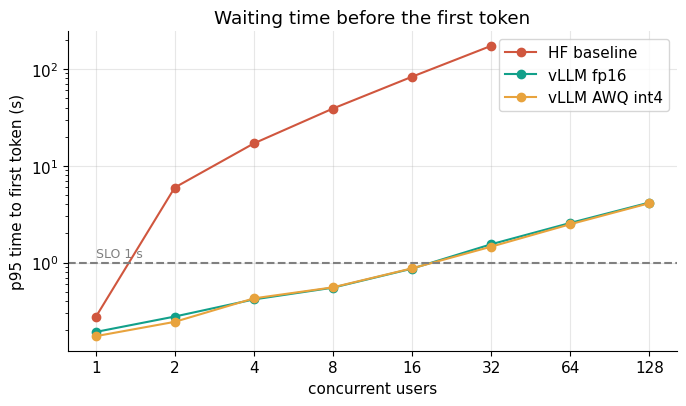

In [12]:
service_s = OUT_TOKENS / val("E0_hf_fp16", 1)          # seconds to serve one request on its own
rows = []
for u in users_of("E0_hf_fp16"):
    rows.append({"users": u, "throughput_tok_s": val("E0_hf_fp16", u),
                 "ttft_p50_s": val("E0_hf_fp16", u, "ttft_p50_mean"), "ttft_p95_s": val("E0_hf_fp16", u, "ttft_p95_mean"),
                 "queueing_prediction_s": (u - 1) * service_s})
baseline = pd.DataFrame(rows); baseline.to_csv(PRES_RES / "baseline_queueing.csv", index=False)
print(f"one request alone takes {service_s:.2f} s")
display(baseline.round(2))

fig, ax = plt.subplots(figsize=(7, 4.2))
for cfg in ["E0_hf_fp16", "E3_vllm_fp16", "E4_vllm_awq"]:
    d = S[S.config == cfg].sort_values("users")
    ax.plot(d.users, d.ttft_p95_mean, "o-", color=COL[cfg], label=LBL[cfg])
ax.axhline(SLO_TTFT_S, ls="--", color="grey"); ax.text(1, SLO_TTFT_S * 1.15, "SLO 1 s", color="grey", fontsize=9)
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(users_of("E3_vllm_fp16"), users_of("E3_vllm_fp16"))
ax.set_xlabel("concurrent users"); ax.set_ylabel("p95 time to first token (s)"); ax.set_title("Waiting time before the first token")
ax.legend(); save(fig, "fig_ttft_p95_vs_users")

Throughput is flat at about 23 tokens/s no matter how many users arrive, and the queueing estimate tracks the measured median closely (at 8 users, ~39 s predicted vs ~39 s measured). At 32 users the p95 wait is about three minutes. The measured median is lower than the estimate there only because a 90-second run ends before the queue fully drains. A naive server does not get faster with load; it just builds a queue.

### 9.2 Continuous batching: one weight read, many users

vLLM schedules at every decode step: finished requests leave and waiting ones join immediately, so the GPU always works on as many sequences as memory allows. If decode really is memory-bound, adding users to a step should cost very little, because the weights are read once per step regardless.

,system,users_per_step,step_ms,tokens_per_second
0,HF baseline,1,43.2,23.1
1,vLLM fp16,1,27.7,36.1
2,vLLM fp16,2,30.2,66.1
3,vLLM fp16,4,31.3,127.7
4,vLLM fp16,8,33.3,240.1
5,vLLM fp16,16,37.6,425.6
6,vLLM fp16,32,50.4,634.9
7,vLLM fp16,64,67.6,947.3
8,vLLM fp16,128,106.7,1199.7


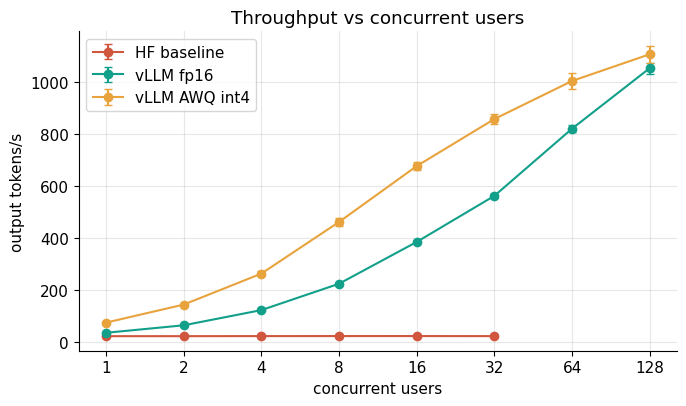

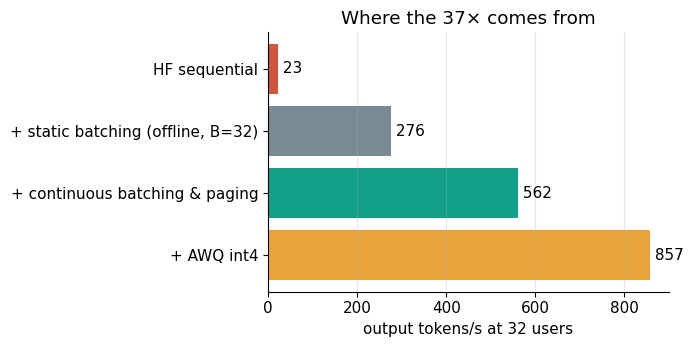

,step,tok_s,x_vs_baseline
0,HF sequential,22.9,1.0
1,"+ static batching (offline, B=32)",275.7,12.0
2,+ continuous batching & paging,562.2,24.5
3,+ AWQ int4,857.4,37.4


In [13]:
steps = pd.DataFrame([{"system": "HF baseline", "users_per_step": 1, "step_ms": 1000 * val("E0_hf_fp16", 1, "tpot_mean_mean")}] +
                     [{"system": "vLLM fp16", "users_per_step": u, "step_ms": 1000 * fp16(u, "tpot_mean_mean")} for u in users_of("E3_vllm_fp16")])
steps["tokens_per_second"] = steps.users_per_step / (steps.step_ms / 1000)
steps.to_csv(PRES_RES / "batching_step_times.csv", index=False)
display(steps.round(1))

fig, ax = plt.subplots(figsize=(7, 4.2))
for cfg in ["E0_hf_fp16", "E3_vllm_fp16", "E4_vllm_awq"]:
    d = S[S.config == cfg].sort_values("users")
    y = [fp16(u) if cfg == "E3_vllm_fp16" else v for u, v in zip(d.users, d.out_tok_per_s_mean)]
    ax.errorbar(d.users, y, yerr=d.out_tok_per_s_std.fillna(0), fmt="o-", capsize=3, color=COL[cfg], label=LBL[cfg])
ax.set_xscale("log", base=2); ax.set_xticks(users_of("E3_vllm_fp16"), users_of("E3_vllm_fp16"))
ax.set_xlabel("concurrent users"); ax.set_ylabel("output tokens/s"); ax.set_title("Throughput vs concurrent users"); ax.legend()
save(fig, "fig_throughput_vs_users")

# attribution of the gain at 32 users
static = {r["batch"]: r for r in json.loads(Path("results/profiling/static_batching.json").read_text()) if not r.get("oom")}
attr = pd.DataFrame({"step": ["HF sequential", "+ static batching (offline, B=32)", "+ continuous batching & paging", "+ AWQ int4"],
                     "tok_s": [val("E0_hf_fp16", 32), static[32]["out_tok_per_s"], val("E3_vllm_fp16", 32), val("E4_vllm_awq", 32)]})
attr["x_vs_baseline"] = attr.tok_s / attr.tok_s.iloc[0]
attr.to_csv(PRES_RES / "attribution_32_users.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(attr.step, attr.tok_s, color=["#D0563E", "#7A8A94", "#12A08A", "#E8A33D"]); ax.invert_yaxis()
for i, v in enumerate(attr.tok_s): ax.text(v, i, f" {v:.0f}", va="center")
ax.set_xlabel("output tokens/s at 32 users"); ax.set_title("Where the 37× comes from"); ax.grid(axis="y", visible=False)
save(fig, "fig_attribution")
display(attr.round(1))

This is the memory-bound argument in numbers: one user costs about 43 ms per step on the baseline; 32 users cost about 50 ms per step on vLLM, so the GPU produces 32 tokens for roughly 17% more time. That gives **24.5× throughput at 32 users**. The price is that each individual user streams a little slower.

The attribution chart splits the gain. Static batching alone gets about 12×. Continuous batching with paged memory roughly doubles that, and AWQ adds another 1.5×. One caveat: the static-batching number comes from an offline test with equal-length requests, which is the best case for static batching, so the middle step is if anything understated.

### 9.3 Memory management: the KV cache decides how many users fit

Each token a user has in flight needs keys and values stored for every layer:

KV bytes per token = 2 × layers × KV heads × head size × bytes = 2 × 36 × 2 × 128 × 2 = **36,864 bytes (36 KiB)**

Qwen2.5-3B uses only 2 KV heads (grouped-query attention), which keeps this small. Whatever GPU memory the weights do not take becomes vLLM's KV-cache pool, and PagedAttention hands it out in fixed blocks (64 tokens on this GPU) as sequences grow, instead of reserving the maximum length for each request.

,config,budget_GiB,weights_GiB,runtime_GiB,activations_GiB,cuda_graphs_GiB,kv_pool_GiB,kv_tokens
0,vLLM fp16,13.11,5.79,0.27,0.24,0.51,6.05,176128
1,vLLM AWQ int4,13.11,1.95,0.25,0.56,0.55,9.77,284672


fp16 KV pool: 176,128 tokens = 6.05 GiB -> 36,883 bytes per token
reserving 4,096 tokens per request would fit 43 users
an average request here holds 238 tokens; 128 users hold ~30,424 tokens (17% of the pool)
HF static batching: +3.6 GiB for 64 sequences whose KV needs 1.4 GiB


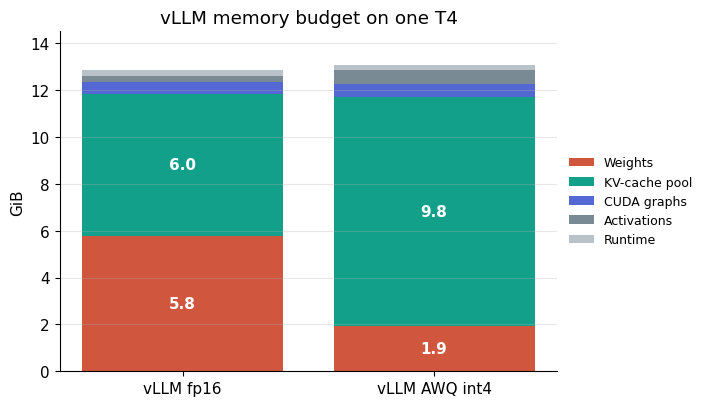

In [14]:
def log_text(cfg, i=0):
    p = Path(f"results/logs/{cfg}_server{i}.log")
    return p.read_text(errors="ignore") if p.exists() else ""

def first(pattern, text, cast=float, group=1):
    m = re.search(pattern, text)
    return cast(m.group(group)) if m else float("nan")

def kv_tokens(cfg):
    total = 0
    for i in range(2):
        t = log_text(cfg, i)
        n = first(r"GPU KV cache size: ([\d,]+) tokens", t, cast=lambda s: int(s.replace(",", "")))
        total += 0 if np.isnan(n) else n
    return total

budget = []
for cfg in ["E3_vllm_fp16", "E4_vllm_awq"]:
    t = log_text(cfg)
    weights = first(r"Model loading took ([\d.]+) GiB", t)
    consumed = first(r"Actual usage is ([\d.]+) GiB for consumed memory", t)
    budget.append({"config": LBL[cfg],
                   "budget_GiB": first(r"Desired GPU memory utilization is \([\d.]+, ([\d.]+) GiB\)", t),
                   "weights_GiB": weights, "runtime_GiB": consumed - weights,
                   "activations_GiB": first(r"([\d.]+) GiB for peak activation", t),
                   "cuda_graphs_GiB": first(r"Graph capturing finished in \d+ secs, took ([\d.]+) GiB", t),
                   "kv_pool_GiB": first(r"\d+ KV cache blocks \(([\d.]+) GiB\)", t),
                   "kv_tokens": kv_tokens(cfg)})
budget = pd.DataFrame(budget); budget.to_csv(PRES_RES / "memory_budget.csv", index=False)
display(budget.round(2))

kv_tok = int(budget.kv_tokens.iloc[0]); mean_req = st.mean(lens) + OUT_TOKENS
print(f"fp16 KV pool: {kv_tok:,} tokens = {budget.kv_pool_GiB.iloc[0]:.2f} GiB "
      f"-> {budget.kv_pool_GiB.iloc[0] * 2**30 / kv_tok:,.0f} bytes per token")
print(f"reserving 4,096 tokens per request would fit {kv_tok // 4096} users")
print(f"an average request here holds {mean_req:.0f} tokens; 128 users hold ~{128 * mean_req:,.0f} tokens "
      f"({100 * 128 * mean_req / kv_tok:.0f}% of the pool)")
b1, b64 = static[1]["peak_mem_gib"], static[64]["peak_mem_gib"]
need = 64 * (512 + OUT_TOKENS) * 36864 / 2**30
print(f"HF static batching: +{b64 - b1:.1f} GiB for 64 sequences whose KV needs {need:.1f} GiB")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
parts = [("weights_GiB", "Weights", "#D0563E"), ("kv_pool_GiB", "KV-cache pool", "#12A08A"),
         ("cuda_graphs_GiB", "CUDA graphs", "#5468D4"), ("activations_GiB", "Activations", "#7A8A94"), ("runtime_GiB", "Runtime", "#B8C2C8")]
bottom = np.zeros(len(budget))
for col, name, c in parts:
    ax.bar(budget.config, budget[col], bottom=bottom, color=c, label=name)
    for i, v in enumerate(budget[col]):
        if v > 1: ax.text(i, bottom[i] + v / 2, f"{v:.1f}", ha="center", va="center", color="white", fontweight="bold")
    bottom += budget[col].values
ax.set_ylabel("GiB"); ax.set_title("vLLM memory budget on one T4"); ax.set_ylim(0, 14.5)
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False); ax.grid(axis="x", visible=False)
save(fig, "fig_memory_budget")

The log agrees with the formula: 6.05 GiB for 176,128 tokens works out to about 36.9 KB per token, the 36,864 bytes predicted (the GiB figure in the log is rounded). If every request reserved a 4,096-token maximum, only 43 users would fit. With paging, the 128-user runs used roughly 30k of the 176k available tokens. The naive HF path, by contrast, needed 3.6 GiB of extra memory for 64 sequences whose KV cache is only 1.4 GiB (the rest is temporary buffers and cache copies).

The AWQ bar shows the second half of the story: smaller weights mean a bigger KV pool, about 1.6× more tokens on the same card.

### 9.4 Quantisation: a big win only while decode is memory-bound

AWQ stores the weights in 4 bits (≈2 GiB instead of 5.8 GiB) and de-quantises them inside the matrix kernels. If decode is limited by reading weights, fewer bytes should mean faster steps, but the advantage should shrink as larger batches shift the work towards per-sequence compute.

,users,fp16_tok_s,awq_tok_s,fp16_tpot_ms,awq_tpot_ms,awq_speedup
0,1,35.76,74.79,27.72,12.98,2.09
1,2,64.49,144.06,30.24,13.22,2.23
2,4,122.94,263.19,31.31,13.99,2.14
3,8,224.22,461.63,33.32,15.10,2.06
4,16,384.98,676.58,37.59,20.04,1.76
5,32,562.20,857.37,50.40,31.42,1.53
6,64,820.43,1003.63,67.56,52.59,1.22
7,128,1053.01,1106.38,106.69,98.91,1.05


,config,kv_tokens,vs_fp16
0,vLLM fp16,176128,1.00
1,"vLLM fp16, no CUDA graphs",190464,1.08
2,vLLM AWQ int4,284672,1.62
3,2 replicas (2 GPUs),352256,2.00
4,TP=2 (2 GPUs),495616,2.81


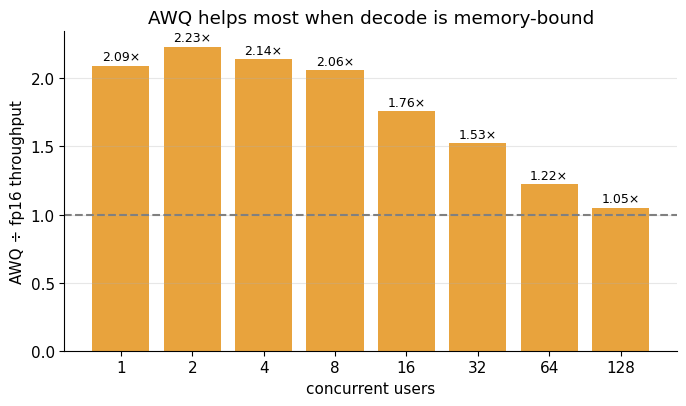

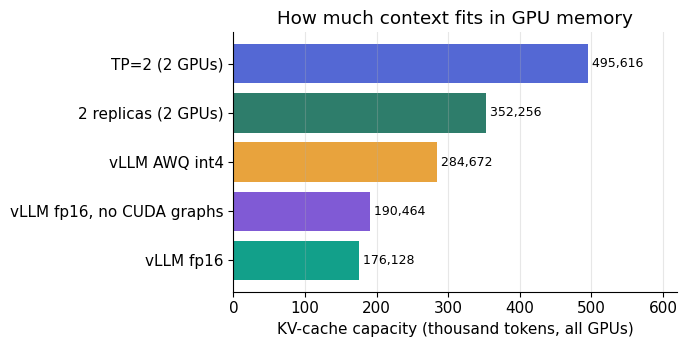

In [15]:
quant = pd.DataFrame([{"users": u, "fp16_tok_s": fp16(u), "awq_tok_s": val("E4_vllm_awq", u),
                       "fp16_tpot_ms": 1000 * fp16(u, "tpot_mean_mean"), "awq_tpot_ms": 1000 * val("E4_vllm_awq", u, "tpot_mean_mean")}
                      for u in users_of("E4_vllm_awq")])
quant["awq_speedup"] = quant.awq_tok_s / quant.fp16_tok_s
quant.to_csv(PRES_RES / "quantisation_speedup.csv", index=False)
display(quant.round(2))

kv = pd.DataFrame([{"config": LBL[c], "kv_tokens": kv_tokens(c)} for c in
                   ["E3_vllm_fp16", "E6_vllm_fp16_eager", "E4_vllm_awq", "E7b_vllm_fp16_2replicas", "E7a_vllm_fp16_tp2"]])
kv["vs_fp16"] = kv.kv_tokens / kv.kv_tokens.iloc[0]
kv.to_csv(PRES_RES / "kv_capacity.csv", index=False)
display(kv.round(2))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar([str(u) for u in quant.users], quant.awq_speedup, color=COL["E4_vllm_awq"])
for i, v in enumerate(quant.awq_speedup): ax.text(i, v + 0.04, f"{v:.2f}×", ha="center", fontsize=9)
ax.axhline(1, color="grey", ls="--"); ax.set_xlabel("concurrent users"); ax.set_ylabel("AWQ ÷ fp16 throughput")
ax.set_title("AWQ helps most when decode is memory-bound"); ax.grid(axis="x", visible=False)
save(fig, "fig_quant_speedup")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(kv.config, kv.kv_tokens / 1000, color=["#12A08A", "#805AD5", "#E8A33D", "#2E7D6B", "#5468D4"])
for i, v in enumerate(kv.kv_tokens): ax.text(v / 1000, i, f" {v:,}", va="center", fontsize=9)
ax.set_xlabel("KV-cache capacity (thousand tokens, all GPUs)"); ax.set_title("How much context fits in GPU memory")
ax.grid(axis="y", visible=False); ax.set_xlim(0, kv.kv_tokens.max() / 1000 * 1.25)
save(fig, "fig_kv_capacity")

The curve behaves as predicted: about **2.1× at one or two users, falling steadily to 1.05× at 128 users**. Weights shrank 3×, but steps only got about 1.6–2× faster, because the parts of each step that do not depend on weight size (KV reads, attention, de-quantisation work, scheduling) remain. Together with the +6.6% perplexity from section 7, the practical conclusion is that AWQ is clearly worth it for a lightly to moderately loaded service, mainly as a memory win at high load.

### 9.5 Prefix caching, and a control experiment

Prefix caching lets a request reuse the KV blocks of an identical earlier prefix instead of recomputing them. It only matches **whole blocks**, and on this GPU a block is 64 tokens. Qwen's system prompt plus chat formatting is shorter than that, so the system prompt alone can never be cached here. Any hits must come from repeated prompts, and my 200 prompts do repeat within a 90-second run. So I treat E5 as an upper bound.

E5 also ran in a different Kaggle session from E3, which is how I noticed the single-user anomaly: E3 measured ~50 ms per token at one user, E5 ~28 ms, yet the two agreed at 8 users. The control runs C3 and C5 repeat both settings back to back in one session.

In [16]:
hits = [float(x) for x in re.findall(r"Prefix cache hit rate: ([\d.]+)%", log_text("E5_vllm_fp16_prefix_cache"))]
print(f"E5 prefix-cache hit rate (vLLM reports it cumulatively): {hits[-1]:.1f}% at the end of the run" if hits else "no hit-rate lines found")

rows = []
for a, b, label in [("E3_vllm_fp16", "E5_vllm_fp16_prefix_cache", "different sessions"),
                    ("C3_control_nocache", "C5_control_cache", "same session (control)")]:
    for u in sorted(set(users_of(a)) & set(users_of(b))):
        rows.append({"comparison": label, "users": u,
                     "tpot_off_ms": 1000 * val(a, u, "tpot_mean_mean"), "tpot_on_ms": 1000 * val(b, u, "tpot_mean_mean"),
                     "ttft_p50_off_s": val(a, u, "ttft_p50_mean"), "ttft_p50_on_s": val(b, u, "ttft_p50_mean"),
                     "ttft_p95_off_s": val(a, u, "ttft_p95_mean"), "ttft_p95_on_s": val(b, u, "ttft_p95_mean"),
                     "throughput_gain": val(b, u) / val(a, u)})
prefix = pd.DataFrame(rows); prefix.to_csv(PRES_RES / "prefix_caching_and_control.csv", index=False)
display(prefix.round(3))

E5 prefix-cache hit rate (vLLM reports it cumulatively): 68.3% at the end of the run


,comparison,users,tpot_off_ms,tpot_on_ms,ttft_p50_off_s,ttft_p50_on_s,ttft_p95_off_s,ttft_p95_on_s,throughput_gain
0,different sessions,1,51.206,28.940,0.060,0.048,0.192,0.141,1.759
1,different sessions,8,33.324,31.810,0.326,0.161,0.551,0.314,1.084
2,different sessions,32,50.398,45.469,0.872,0.297,1.546,0.451,1.198
3,different sessions,64,67.560,56.154,1.365,0.654,2.567,0.783,1.296
4,same session (control),1,27.721,28.555,0.045,0.046,0.159,0.115,0.971
5,same session (control),2,29.131,29.126,0.084,0.078,0.230,0.145,1.004
6,same session (control),8,31.622,31.536,0.261,0.155,0.541,0.329,1.026


The control settles it. In one session, caching off and on give **27.7 vs 28.6 ms per token** at one user, so prefix caching does not change decode speed, and E3's 50 ms was a session outlier. That is why the analysis substitutes C3 for that point, and why "compare within one session when it matters" became a rule for me. Across sessions, throughput varied by roughly 3–7%.

What prefix caching does change is the wait for the first token. Even in the same session, median TTFT at 8 users drops from 0.26 to 0.15 s, and in the full E5 sweep p95 TTFT at 32 users falls from 1.55 to 0.45 s. Skipping prefill also shortens the mixed prefill/decode steps that slow everyone else down. The throughput gain is small at low load (1.03× in the control) and larger at high load (1.2–1.3×), with the repeated-prompt caveat above.

### 9.6 Two GPUs: tensor parallelism vs replicas

There are two obvious ways to use the second T4:

- **Tensor parallelism (TP=2):** split every layer across both GPUs. Each GPU reads half the weights per step, so steps get faster, but every layer needs two all-reduce operations over PCIe.
- **Two replicas:** run two independent copies and split users between them. There is no communication at all, but each copy only sees half the users.

,users,one_gpu_tok_s,tp2_tok_s,replicas_tok_s,tp2_speedup,replicas_speedup,tp2_efficiency,replicas_efficiency,replicas_predicted_2x_half_load,tp2_p95_ttft_s,replicas_p95_ttft_s
0,8,224.22,387.05,249.03,1.73,1.11,0.86,0.56,245.88,0.32,0.37
1,32,562.20,893.32,766.44,1.59,1.36,0.79,0.68,769.96,0.88,0.95
2,64,820.43,1268.85,1135.85,1.55,1.38,0.77,0.69,1124.39,1.49,1.64
3,128,1053.01,1562.85,1638.05,1.48,1.56,0.74,0.78,1640.86,2.54,2.48


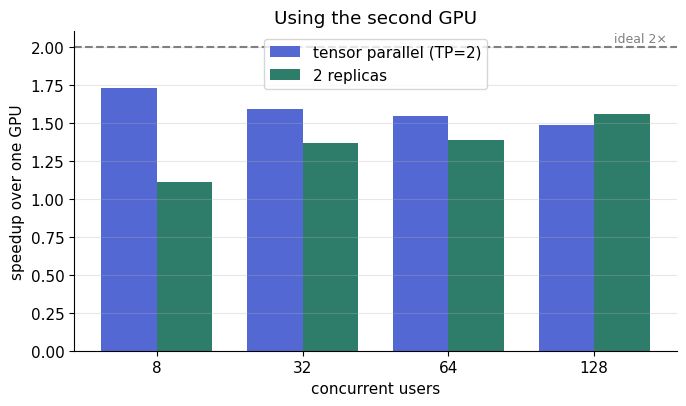

In [17]:
rows = []
# 1-user runs are left out: E7a/E7b ran in the same session as the E3 single-user outlier (section 9.5)
for u in [u for u in sorted(set(users_of("E7a_vllm_fp16_tp2")) & set(users_of("E7b_vllm_fp16_2replicas"))) if u >= 8]:
    base = fp16(u)
    tp, rep = val("E7a_vllm_fp16_tp2", u), val("E7b_vllm_fp16_2replicas", u)
    half = fp16(u // 2) if u >= 2 and u // 2 in users_of("E3_vllm_fp16") else float("nan")
    rows.append({"users": u, "one_gpu_tok_s": base, "tp2_tok_s": tp, "replicas_tok_s": rep,
                 "tp2_speedup": tp / base, "replicas_speedup": rep / base,
                 "tp2_efficiency": tp / base / 2, "replicas_efficiency": rep / base / 2,
                 "replicas_predicted_2x_half_load": 2 * half,
                 "tp2_p95_ttft_s": val("E7a_vllm_fp16_tp2", u, "ttft_p95_mean"),
                 "replicas_p95_ttft_s": val("E7b_vllm_fp16_2replicas", u, "ttft_p95_mean")})
scaling = pd.DataFrame(rows); scaling.to_csv(PRES_RES / "scaling.csv", index=False)
display(scaling.round(2))

fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(scaling)); w = 0.38
ax.bar(x - w / 2, scaling.tp2_speedup, w, color=COL["E7a_vllm_fp16_tp2"], label="tensor parallel (TP=2)")
ax.bar(x + w / 2, scaling.replicas_speedup, w, color=COL["E7b_vllm_fp16_2replicas"], label="2 replicas")
ax.axhline(2, ls="--", color="grey"); ax.text(len(x) - 0.5, 2.03, "ideal 2×", ha="right", color="grey", fontsize=9)
ax.set_xticks(x, scaling.users); ax.set_xlabel("concurrent users"); ax.set_ylabel("speedup over one GPU")
ax.set_title("Using the second GPU"); ax.legend(); ax.grid(axis="x", visible=False)
save(fig, "fig_scaling_speedup")

I start this comparison at 8 users: the two-GPU runs shared a session with the single-user outlier described in section 9.5, so their 1-user points are not trustworthy. From 8 users up, the replicas behave exactly as theory says they should: two replicas at N users match twice the single-GPU throughput at N/2 users, within about 2%, and they overtake TP only at the highest load. TP is ahead everywhere below that, because halving the weight read makes every token faster, but its efficiency falls from about 0.86 to 0.74 as the per-step all-reduces add up. Section 9.8 puts a number on that communication cost.

Which one is "better" depends on what you optimise, and section 9.7 makes that concrete.

### 9.7 Throughput vs goodput: what users actually get

Throughput counts every token. Goodput only counts tokens from requests that met the SLO (first token within 1 s, under 100 ms per token after that). The gap between the two is what the serving system's users actually feel, and it is also what capacity and cost should be planned on.

cost uses an illustrative $0.35/GPU-hour


,config,gpus,peak_goodput_tok_s,at_users,max_throughput_tok_s,usd_per_million_tokens
0,HF baseline,1,22.693,1,23.140,4.284
1,vLLM fp16,1,376.322,16,1053.012,0.258
2,vLLM AWQ int4,1,659.409,16,1106.377,0.147
3,vLLM fp16 + prefix cache,1,1063.370,64,1063.370,0.091
4,2 replicas (2 GPUs),2,767.415,64,1638.046,0.253
5,TP=2 (2 GPUs),2,1027.920,64,1562.855,0.189


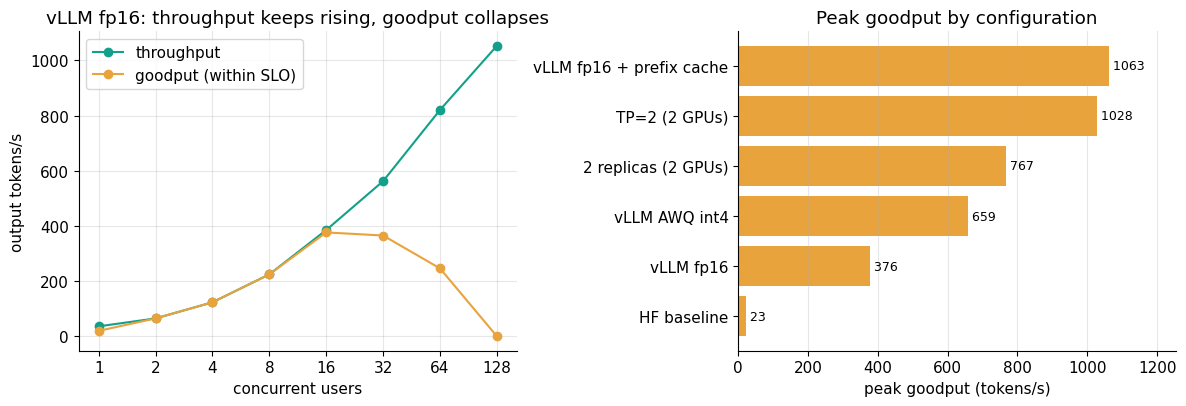

In [18]:
n_gpus = {c: 2 if c.startswith("E7") else 1 for c in S.config.unique()}
rows = []
for cfg in ["E0_hf_fp16", "E3_vllm_fp16", "E4_vllm_awq", "E5_vllm_fp16_prefix_cache", "E7b_vllm_fp16_2replicas", "E7a_vllm_fp16_tp2"]:
    d = S[S.config == cfg]
    best = d.loc[d.goodput_tok_s.idxmax()]
    tok_per_hour = best.goodput_tok_s * 3600
    rows.append({"config": LBL[cfg], "gpus": n_gpus[cfg], "peak_goodput_tok_s": best.goodput_tok_s,
                 "at_users": int(best.users), "max_throughput_tok_s": d.out_tok_per_s_mean.max(),
                 "usd_per_million_tokens": GPU_PRICE_HR * n_gpus[cfg] / tok_per_hour * 1e6})
goodput = pd.DataFrame(rows); goodput.to_csv(PRES_RES / "goodput_and_cost.csv", index=False)
print(f"cost uses an illustrative ${GPU_PRICE_HR}/GPU-hour")
display(goodput.round(3))

d = S[S.config == "E3_vllm_fp16"].sort_values("users")
tput = [fp16(u) for u in d.users]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(d.users, tput, "o-", color=COL["E3_vllm_fp16"], label="throughput")
ax.plot(d.users, d.goodput_tok_s, "o-", color=COL["E4_vllm_awq"], label="goodput (within SLO)")
ax.set_xscale("log", base=2); ax.set_xticks(d.users, d.users); ax.set_xlabel("concurrent users"); ax.set_ylabel("output tokens/s")
ax.set_title("vLLM fp16: throughput keeps rising, goodput collapses"); ax.legend()
ax = axes[1]
g = goodput.sort_values("peak_goodput_tok_s")
ax.barh(g.config, g.peak_goodput_tok_s, color=COL["E4_vllm_awq"])
for i, v in enumerate(g.peak_goodput_tok_s): ax.text(v, i, f" {v:.0f}", va="center", fontsize=9)
ax.set_xlabel("peak goodput (tokens/s)"); ax.set_title("Peak goodput by configuration"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, g.peak_goodput_tok_s.max() * 1.18)
save(fig, "fig_goodput")

This is the result I find most useful in practice. On one T4, vLLM fp16 throughput keeps climbing to over 1,000 tokens/s at 128 users, but **goodput peaks at about 16 users and then collapses to zero**. Past that point the GPU is busier but nobody is being served within the SLO. The real capacity of the card is about 16 concurrent users, not 128.

It also refines the two-GPU comparison. Replicas win on raw throughput at 128 users, but by then neither layout meets the SLO. Within the SLO, **TP=2 delivers the most goodput of any fp16 setup (≈1,030 vs ≈770 tokens/s)** because it keeps each token fast. Costed at the peak goodput, serving drops from about $4 per million tokens for the naive baseline to about $0.15 with AWQ (with an illustrative GPU price — the ratio is what matters).

### 9.8 One model that explains the results

All of the above can be summarised by a very simple model of a decode step:

**step time ≈ t₀ + k × B**

where t₀ is a fixed cost paid once per step regardless of batch size (dominated by reading all the weights) and k is the extra cost of each concurrent user B (its attention over its own KV cache, sampling, scheduling). `analysis/perf_model.py` fits this to the measured time-per-token of fp16, AWQ and TP=2.

# Two-term decode model: step time = t0 + k × users

| Config | t0 (ms) | k (ms/user) | R² | effective BW (GB/s) | % of peak BW | critical batch t0/k |
|---|---|---|---|---|---|---|
| E3_vllm_fp16 | 28.6 | 0.613 | 0.998 | 218 | 68% | 47 |
| E4_vllm_awq | 10.6 | 0.681 | 0.998 | 198 | 62% | 16 |
| E7a_vllm_fp16_tp2 | 17.1 | 0.437 | 0.998 | 182 | 57% | 39 |

## AWQ vs fp16 speedup: model vs measured

| Users | Model | Measured |
|---|---|---|
| 8 | 2.09× | 2.06× |
| 16 | 1.79× | 1.76× |
| 32 | 1.49× | 1.53× |
| 64 | 1.25× | 1.22× |
| 128 | 1.10× | 1.05× |

Predicted crossover (fp16 faster than AWQ) above ≈ 266 concurrent sequences (prediction, beyond the measured range).

## Tensor parallel overhead
Ideal TP=2 fixed cost 14.3 ms; measured 17.1 ms → 2.8 ms per step ≈ 39 µs per all-reduce (72 all-reduces per step). Per-user cost 0.437 vs 0.613 ms (ideal 0.306).

## Which SLO binds?
TPOT alone would allow ≈ 117 users (fp16) and ≈ 131 users (AWQ) before TPOT > 100 ms; measured goodput peaks far earlier, so first-token latency (TTFT) is the binding constraint.

## At 128 users (fp16)
Step 107 ms; compute utilisation (MFU) ≈ 11%; reading all KV caches at peak bandwidth would take only ≈ 3.5 ms. The per-user cost is therefore not KV bandwidth but per-sequence kernel and software overhead.

## Energy per output token (J)

| Users | C3_control_nocache | C5_control_cache | E0_hf_fp16 | E3_vllm_fp16 | E4_vllm_awq | E5_vllm_fp16_prefix_cache | E6_vllm_fp16_eager | E7a_vllm_fp16_tp2 | E7b_vllm_fp16_2replicas |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1.911 | 1.963 | 2.926 | 3.374 | 0.881 | 1.983 | 2.810 | 2.328 | 4.908 |
| 2 | 1.008 | 1.006 | 2.931 | 1.028 | 0.461 |  |  |  |  |
| 4 |  |  | 2.889 | 0.538 | 0.253 |  |  |  |  |
| 8 | 0.282 | 0.276 | 2.882 | 0.295 | 0.144 | 0.276 | 0.380 | 0.344 | 0.533 |
| 16 |  |  | 2.880 | 0.172 | 0.098 |  |  |  |  |
| 32 |  |  | 2.903 | 0.118 | 0.077 | 0.099 | 0.118 | 0.149 | 0.172 |
| 64 |  |  |  | 0.080 | 0.066 | 0.063 |  | 0.105 | 0.116 |
| 128 |  |  |  | 0.063 | 0.060 |  |  | 0.084 | 0.080 |


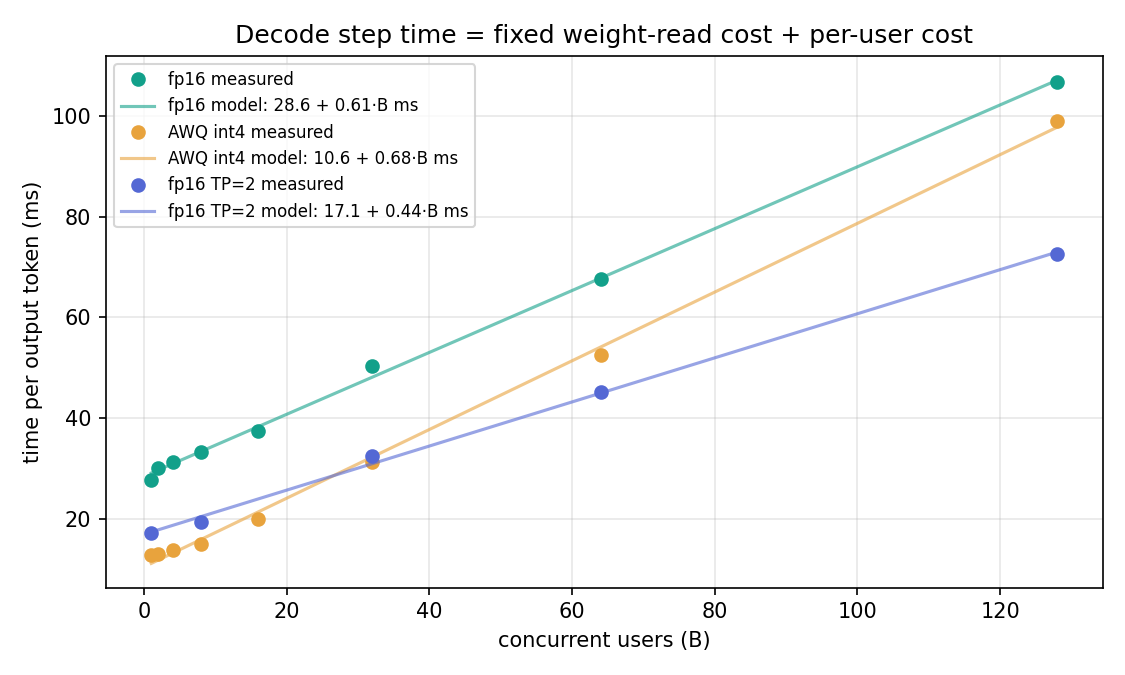

In [19]:
display(Markdown(Path("results/perf_model.md").read_text()))
shutil.copy("plots/perf_model.png", PRES_FIG / "fig_perf_model.png")
display(Image(filename=str(PRES_FIG / "fig_perf_model.png"), width=700))

The fit is very close (R² ≈ 0.998 for all three), and the two parameters mean something physical:

- **t₀ is the weight read.** Dividing weight bytes by t₀ gives about 218 GB/s for fp16 and about 198 GB/s for AWQ: roughly the same effective bandwidth, around two-thirds of the T4's peak. Quantisation shrank t₀ almost exactly in proportion to the bytes it saved.
- **k is per-user overhead, and AWQ makes it slightly worse** (0.68 vs 0.61 ms), which is the de-quantisation work. That is why the AWQ advantage fades with load, and the model reproduces the measured speedups (2.09/1.49/1.10× predicted vs 2.06/1.53/1.05× measured at 8/32/128 users) without being fitted to them. It also predicts that fp16 would overtake AWQ above roughly 266 concurrent sequences. That is outside what I measured, so it stays a prediction.
- **TP=2 should halve t₀ but does not quite.** The extra ~2.8 ms per step is the communication: 72 all-reduces per step over PCIe, about 39 µs each.
- **The ceiling at high load is not bandwidth.** At 128 users all KV caches together could be read in a few milliseconds, yet each user adds 0.61 ms, and the GPU reaches only about 11% of its peak compute. The limit there is per-sequence kernel and software overhead on this older architecture.

The model also explains goodput. Time-per-token alone would stay under 100 ms until about 117 users. Goodput collapses far earlier, so **the binding constraint is time-to-first-token** (queueing and prefill interfering with decode), which is exactly what prefix caching relieved.

### 9.9 Energy per token

`nvidia-smi` sampled power every half second during every run.

,mean_power_W
config,
C3_control_nocache,67.8
C5_control_cache,67.9
E0_hf_fp16,66.6
E3_vllm_fp16,66.1
E4_vllm_awq,66.2
E5_vllm_fp16_prefix_cache,67.1
E6_vllm_fp16_eager,66.5
E7a_vllm_fp16_tp2,132.7
E7b_vllm_fp16_2replicas,124.6


config,C3_control_nocache,C5_control_cache,E0_hf_fp16,E3_vllm_fp16,E4_vllm_awq,E5_vllm_fp16_prefix_cache,E6_vllm_fp16_eager,E7a_vllm_fp16_tp2,E7b_vllm_fp16_2replicas
users,,,,,,,,,
1,1.911,1.963,2.926,3.374,0.881,1.983,2.810,2.328,4.908
2,1.008,1.006,2.931,1.028,0.461,NaN,NaN,NaN,NaN
4,NaN,NaN,2.889,0.538,0.253,NaN,NaN,NaN,NaN
8,0.282,0.276,2.882,0.295,0.144,0.276,0.380,0.344,0.533
16,NaN,NaN,2.880,0.172,0.098,NaN,NaN,NaN,NaN
32,NaN,NaN,2.903,0.118,0.077,0.099,0.118,0.149,0.172
64,NaN,NaN,NaN,0.080,0.066,0.063,NaN,0.105,0.116
128,NaN,NaN,NaN,0.063,0.060,NaN,NaN,0.084,0.080


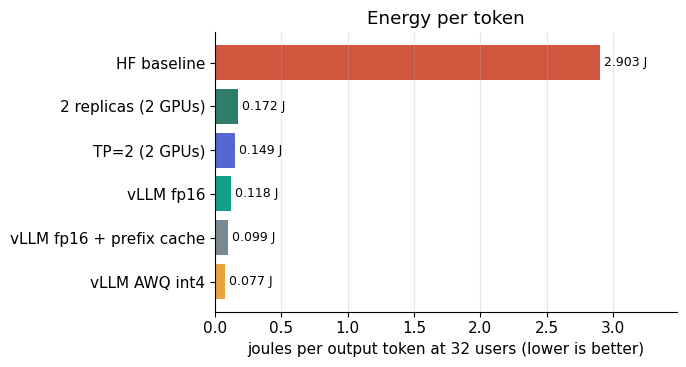

In [20]:
energy = S.pivot_table(index="users", columns="config", values="joules_per_token_mean")
power = S.groupby("config").gpu_power_mean_w_mean.mean().rename("mean_power_W")
energy.to_csv(PRES_RES / "energy_joules_per_token.csv")
power.to_csv(PRES_RES / "mean_power_per_config.csv")
display(power.round(1).to_frame())
display(energy.round(3))

order = ["E0_hf_fp16", "E7b_vllm_fp16_2replicas", "E7a_vllm_fp16_tp2", "E3_vllm_fp16", "E5_vllm_fp16_prefix_cache", "E4_vllm_awq"]
e32 = pd.Series({LBL[c]: val(c, 32, "joules_per_token_mean") for c in order})
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(e32.index, e32.values, color=[COL[c] for c in order]); ax.invert_yaxis()
for i, v in enumerate(e32.values): ax.text(v, i, f" {v:.3f} J", va="center", fontsize=9)
ax.set_xlabel("joules per output token at 32 users (lower is better)"); ax.set_title("Energy per token")
ax.grid(axis="y", visible=False); ax.set_xlim(0, e32.max() * 1.2)
save(fig, "fig_energy")

A busy T4 drew about 66 W per GPU in every configuration and at every load, even when the baseline was serving a single user at 23 tokens/s. With power essentially constant, energy per token is just power divided by throughput. The baseline spends about **2.9 J per token**, AWQ at high load about **0.06 J**: roughly 48× less. Memory-bound decode burns nearly full power while the compute units wait, so batching and quantisation are energy optimisations as much as speed ones. One quantised T4 was also more energy-efficient per token than either two-GPU layout.

Logged clock-event counters showed about 17 s of software power capping, so the cards were genuinely running at their power limit.

## 10. Packaging everything for the presentation

The final cell collects every table and figure the slides and the report use, writes a short manifest describing each file, and zips the lot into `/kaggle/working/presentation_assets.zip` (download it from the Output panel). Raw per-request logs stay out of the zip; they are in the repository.

In [21]:
import zipfile, datetime

include = []
include += sorted(PRES_RES.glob("*"))                       # tables computed in this notebook
include += sorted(PRES_FIG.glob("*.png"))                   # slide-ready figures
include += sorted(Path("plots").glob("*.png"))              # standard figures from make_plots.py
include += [Path(p) for p in ["results/summary.csv", "results/summary_runs.csv", "results/headline_table.md",
                              "results/perf_model.csv", "results/perf_model.md", "results/kv_capacity.csv",
                              "results/quant_speedup.csv", "results/scaling.csv"] if Path(p).exists()]
include += sorted(Path("results/eval").glob("ppl_*.json")) + sorted(Path("results/eval").glob("agreement_*.json"))
include += sorted(Path("results/profiling").glob("*.json")) + sorted(Path("results/profiling").glob("*.txt"))

descriptions = {
    "hardware.json": "GPU, software versions and datasheet peaks",
    "accuracy.csv": "perplexity and output agreement (fp16 re-run and AWQ)",
    "baseline_queueing.csv": "HF baseline: throughput, TTFT and the queueing prediction",
    "batching_step_times.csv": "decode step time vs users per step",
    "attribution_32_users.csv": "throughput gain broken into steps at 32 users",
    "memory_budget.csv": "vLLM memory budget from the server logs",
    "quantisation_speedup.csv": "AWQ vs fp16 throughput and step time per load level",
    "kv_capacity.csv": "KV-cache capacity in tokens per configuration",
    "prefix_caching_and_control.csv": "prefix caching on/off, across sessions and same-session control",
    "scaling.csv": "TP=2 vs replicas: speedup, efficiency, latency",
    "goodput_and_cost.csv": "peak goodput and cost per million tokens",
    "energy_joules_per_token.csv": "energy per output token by configuration and load",
    "mean_power_per_config.csv": "average GPU power per configuration",
    "summary.csv": "all metrics, mean and std over repeats", "summary_runs.csv": "all metrics, one row per run",
    "perf_model.md": "two-term performance model report", "perf_model.csv": "model parameters",
}
manifest = ["# Presentation assets", f"Generated {datetime.datetime.now():%Y-%m-%d %H:%M} from commit "
            + subprocess.run("git rev-parse --short HEAD", shell=True, capture_output=True, text=True).stdout.strip(), ""]
for p in include:
    manifest.append(f"- `{p}`" + (f": {descriptions[p.name]}" if p.name in descriptions else ""))
(PRES_RES / "MANIFEST.md").write_text("\n".join(manifest) + "\n")
include.append(PRES_RES / "MANIFEST.md")

zip_path = WORK_DIR / "presentation_assets.zip" if WORK_DIR.exists() else Path("presentation_assets.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in dict.fromkeys(include):            # keep order, drop duplicates
        z.write(p, arcname=str(p))
print(f"{zip_path}  ({zip_path.stat().st_size / 1e6:.1f} MB, {len(set(include))} files)")
print("\n".join(manifest[3:]))

/kaggle/working/presentation_assets.zip  (1.6 MB, 52 files)
- `results/presentation/MANIFEST.md`
- `results/presentation/accuracy.csv`: perplexity and output agreement (fp16 re-run and AWQ)
- `results/presentation/attribution_32_users.csv`: throughput gain broken into steps at 32 users
- `results/presentation/baseline_queueing.csv`: HF baseline: throughput, TTFT and the queueing prediction
- `results/presentation/batching_step_times.csv`: decode step time vs users per step
- `results/presentation/energy_joules_per_token.csv`: energy per output token by configuration and load
- `results/presentation/goodput_and_cost.csv`: peak goodput and cost per million tokens
- `results/presentation/hardware.json`: GPU, software versions and datasheet peaks
- `results/presentation/kv_capacity.csv`: KV-cache capacity in tokens per configuration
- `results/presentation/mean_power_per_config.csv`: average GPU power per configuration
- `results/presentation/memory_budget.csv`: vLLM memory budget from the

## 11. What I take away from this

1. **Measure before optimising.** Profiling showed decode uses about 0.2% of the GPU's compute and is limited by memory bandwidth. Every later result follows from that.
2. **Batching gives the biggest win** (24.5× at 32 users) because one weight read can serve many users. PagedAttention makes the large batches possible by not reserving memory a request will never use.
3. **Quantisation helps most at low load** (≈2.1×), fading to almost nothing at 128 users, but it always buys memory: 1.6× more KV-cache capacity, for +6.6% perplexity.
4. **Goodput, not throughput, is the capacity number.** One T4 serves about 16 users within the SLO, and first-token latency is the constraint that breaks first.
5. **The second GPU should be used according to the goal.** TP=2 gives the most goodput within the SLO; replicas give the most raw throughput at very high load.
6. **A two-term model** (fixed weight-read cost + per-user cost) explains all of the above with two numbers per configuration, and it puts numbers on things I could not measure directly, such as the cost of a single all-reduce.

**Limitations.** The Kaggle VM is small (4 vCPUs shared by client and server) and the GPUs run at their power cap. Throughput varies by a few percent between sessions, so the comparisons that mattered were repeated within one session. The prefix-caching result is an upper bound because prompts repeat. The static-batching comparison is offline and best-case.

**If I had more time or hardware:** test the model's prediction that fp16 overtakes AWQ beyond ~266 concurrent sequences; run prefix caching with a long shared system prompt and unique questions; try FP8 weights and an FP8 KV cache on a newer GPU; and separate prefill and decode onto different GPUs, since first-token latency is what limits capacity here.